# 00 · Reinforcement Learning Foundations: from rewards to Bellman, and why an LLM is a policy

**Who this is for:** you know PyTorch and supervised learning (loss, gradient, optimizer) but have never
studied reinforcement learning (RL). By the end of this notebook you will be able to:

1. describe any RL problem as a **Markov Decision Process (MDP)**;
2. compute **returns**, **value functions** $V^\pi$, $Q^\pi$ and **advantages** $A^\pi$ by hand and in code;
3. derive and implement the **Bellman equations**, **policy evaluation**, **value iteration** and **policy iteration** from scratch;
4. see exactly how *text generation by an LLM* (and a VLM) is the same MDP, which is the foundation for every later notebook (PPO-RLHF, DPO, GRPO, ...).

Where this notebook sits in the course:

```mermaid
flowchart LR
    N00["<b>00 Foundations</b><br/>MDP, Bellman<br/>(you are here)"]:::here --> N01[01 Bandits]
    N01 --> N02[02 Tabular TD / Q-learning]
    N02 --> N03[03 DQN]
    N02 --> N04[04 Policy gradient]
    N04 --> N05[05 Actor-critic, GAE]
    N05 --> N06[06 TRPO / PPO]
    N06 --> N07[07 RLHF]
    N07 --> N08[08 DPO family]
    N07 --> N09[09 GRPO family]
    N09 --> N10[10 Reasoning RLVR]
    N08 --> N11[11 RLAIF / self-play]
    N09 --> N12[12 RL for VLMs]
    N10 --> N13[13 Frontier & pitfalls]
    classDef here fill:#2563eb,color:#fff,stroke:#1e3a8a
```

## 1. What is reinforcement learning?

**Analogy: teaching a dog a trick.** You cannot show the dog the "correct output" for every situation (that
would be supervised learning). Instead the dog *tries something*, and you give a treat (reward) when the
result is good. Over many tries, the dog figures out which behaviours lead to treats. Three things make this
harder than supervised learning:

| Supervised learning | Reinforcement learning |
|---|---|
| Correct label given for every input | Only a scalar **reward**, often much later ("delayed reward") |
| Data is a fixed dataset | Data is generated by **your own behaviour**: change the policy, change the data |
| Each example independent | Actions change future states (**sequential decisions**) |
| Loss tells you *what* the answer is | Reward tells you *how good* it was, not what would have been better |

The core loop is always the same: an **agent** observes a **state**, picks an **action**, and the
**environment** answers with a **reward** and the next state.

```mermaid
flowchart LR
    A["🤖 Agent<br/>policy π(a|s)"] -- "action aₜ" --> E["🌍 Environment<br/>P(s'|s,a), R(s,a,s')"]
    E -- "reward rₜ₊₁" --> A
    E -- "next state sₜ₊₁" --> A
```

For an LLM: the *agent* is the language model, the *action* is the next token, the *state* is the prompt
plus the tokens generated so far, and the *reward* comes from a reward model, a human, or a verifier
(e.g. "is the final answer to this maths problem correct?"). We make this precise in section 8.

## 2. The Markov Decision Process (MDP)

An MDP is the tuple $(\mathcal{S}, \mathcal{A}, P, R, \gamma)$:

| Symbol | Name | Gridworld example | LLM example |
|---|---|---|---|
| $\mathcal{S}$ | states | cells of the grid | prompt + tokens so far |
| $\mathcal{A}$ | actions | up / right / down / left | the vocabulary |
| $P(s' \mid s, a)$ | transition probabilities | 80% move as intended, 10% slip sideways each | deterministic: append the token |
| $R(s, a, s')$ | reward | +1 goal, -1 pit, -0.04 per step | reward model score at `<eos>`, 0 elsewhere |
| $\gamma \in [0, 1]$ | discount factor | 0.95 | usually 1.0 (episodes are short and finite) |

**The Markov property** says the next state depends only on the current state and action, not on how we
got there: $P(s_{t+1} \mid s_t, a_t, s_{t-1}, \dots) = P(s_{t+1} \mid s_t, a_t)$. For an LLM this holds
trivially because the "state" *is* the whole history of tokens.

A **policy** $\pi(a \mid s)$ is a probability distribution over actions for every state. That is what we
learn. A *deterministic* policy puts all its probability on one action.

Let's build a small, classic gridworld (after Russell & Norvig's 4x3 world) **from scratch in pure Python**.

In [1]:
# Setup: make the shared `rlkit` helpers (plots, GIFs, toy envs, tiny models) importable.
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))
%matplotlib inline

In [2]:
import math
import random
from collections import defaultdict

import matplotlib.pyplot as plt
import numpy as np

from rlkit.viz import COLORS, Animator, asset_path, save_figure, setup_style, show_gif

setup_style()
random.seed(0)

In [3]:
class GridWorld:
    """A stochastic gridworld MDP written in plain Python.

    Layout characters:  'S' start, 'G' goal (+1, terminal), 'P' pit (-1, terminal), '#' wall, '.' free.
    Dynamics: the intended move happens with probability 1 - slip; with probability slip/2 each the agent
    slips to one of the two perpendicular directions. Bumping into a wall/edge leaves you where you are.
    Every non-terminal step costs ``step_reward`` (a small negative reward = "hurry up").
    """

    ACTIONS = [(-1, 0), (0, 1), (1, 0), (0, -1)]   # up, right, down, left
    ARROWS = ["↑", "→", "↓", "←"]

    def __init__(self, layout, slip=0.2, step_reward=-0.04, gamma=0.95):
        self.grid = [row.split() for row in layout]
        self.H, self.W = len(self.grid), len(self.grid[0])
        self.slip, self.step_reward, self.gamma = slip, step_reward, gamma
        self.states = [(r, c) for r in range(self.H) for c in range(self.W) if self.grid[r][c] != "#"]
        self.terminal = {s: (1.0 if self.grid[s[0]][s[1]] == "G" else -1.0)
                         for s in self.states if self.grid[s[0]][s[1]] in "GP"}
        self.start = next(s for s in self.states if self.grid[s[0]][s[1]] == "S")

    def _move(self, s, a):
        r, c = s[0] + self.ACTIONS[a][0], s[1] + self.ACTIONS[a][1]
        if 0 <= r < self.H and 0 <= c < self.W and self.grid[r][c] != "#":
            return (r, c)
        return s  # bumped into a wall / the edge

    def transitions(self, s, a):
        """The model P(s', r | s, a) as a list of (prob, next_state, reward, done)."""
        if s in self.terminal:
            return []
        outcomes = defaultdict(float)
        for direction, p in [(a, 1 - self.slip), ((a + 1) % 4, self.slip / 2), ((a + 3) % 4, self.slip / 2)]:
            outcomes[self._move(s, direction)] += p
        result = []
        for s2, p in outcomes.items():
            reward = self.terminal.get(s2, self.step_reward)
            result.append((p, s2, reward, s2 in self.terminal))
        return result

    def step(self, s, a, rng=random):
        """Sample one transition - this is all a model-free agent ever gets to see."""
        u, acc = rng.random(), 0.0
        for p, s2, r, done in self.transitions(s, a):
            acc += p
            if u <= acc:
                return s2, r, done
        return s2, r, done


LAYOUT = [
    ". . . . G",
    ". # . . P",
    ". # . . .",
    ". . . # .",
    "S . . . .",
]
env = GridWorld(LAYOUT)
print(f"{len(env.states)} states, {len(env.ACTIONS)} actions, terminals: {env.terminal}, start: {env.start}")
print("P(s', r | s=(2,2), a=up):")
for p, s2, r, done in env.transitions((2, 2), 0):
    print(f"   p={p:.2f} -> s'={s2}  r={r:+.2f}  done={done}")

22 states, 4 actions, terminals: {(0, 4): 1.0, (1, 4): -1.0}, start: (4, 0)
P(s', r | s=(2,2), a=up):
   p=0.80 -> s'=(1, 2)  r=-0.04  done=False
   p=0.10 -> s'=(2, 3)  r=-0.04  done=False
   p=0.10 -> s'=(2, 2)  r=-0.04  done=False


Let's draw the world. A small helper renders a value function as a heat-map and a policy as arrows; we
reuse it for every figure and animation in this notebook.

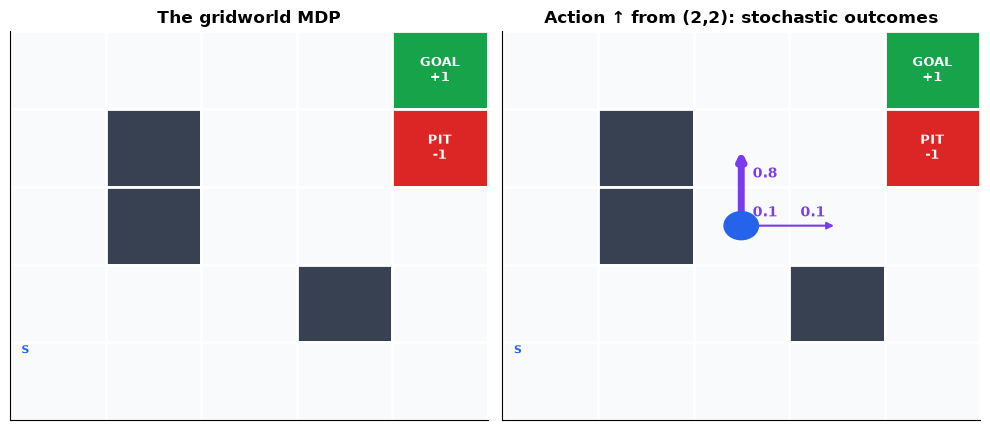

In [4]:
def draw_grid(ax, env, V=None, policy=None, title="", vmin=-1, vmax=1, agent=None, trail=None):
    """Render the gridworld: cell colour = V(s), arrow = greedy action, optional agent position + trail."""
    ax.clear()
    ax.set_xlim(-0.5, env.W - 0.5)
    ax.set_ylim(env.H - 0.5, -0.5)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    cmap = plt.get_cmap("RdYlGn")
    for r in range(env.H):
        for c in range(env.W):
            ch = env.grid[r][c]
            if ch == "#":
                color = "#374151"
            elif ch == "G":
                color = COLORS["reward"]
            elif ch == "P":
                color = COLORS["penalty"]
            elif V is not None:
                color = cmap((V.get((r, c), 0) - vmin) / (vmax - vmin))
            else:
                color = "#f9fafb"
            ax.add_patch(plt.Rectangle((c - 0.5, r - 0.5), 1, 1, fc=color, ec="white", lw=2))
            if ch in "GP":
                ax.text(c, r, "GOAL\n+1" if ch == "G" else "PIT\n-1", ha="center", va="center",
                        fontsize=9, weight="bold", color="white")
            elif ch != "#":
                if V is not None:
                    ax.text(c, r + 0.32, f"{V.get((r, c), 0):+.2f}", ha="center", va="center", fontsize=8)
                if policy is not None and (r, c) in policy:
                    ax.text(c, r - 0.05, env.ARROWS[policy[(r, c)]], ha="center", va="center", fontsize=16)
                if ch == "S":
                    ax.text(c - 0.38, r - 0.36, "S", fontsize=8, weight="bold", color=COLORS["policy"])
    if trail:
        ys, xs = zip(*trail)
        ax.plot(xs, ys, "-", color=COLORS["policy"], lw=2, alpha=0.6)
    if agent is not None:
        ax.add_patch(plt.Circle((agent[1], agent[0]), 0.22, color=COLORS["policy"], zorder=5))
    ax.set_title(title)


fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
draw_grid(axes[0], env, title="The gridworld MDP")
# Right panel: what "slip = 0.2" means for the action UP.
ax = axes[1]
draw_grid(ax, env, title="Action ↑ from (2,2): stochastic outcomes")
for p, s2, r, done in env.transitions((2, 2), 0):
    ax.annotate("", xy=(s2[1], s2[0]), xytext=(2, 2),
                arrowprops=dict(arrowstyle="-|>", color=COLORS["accent"], lw=1 + 5 * p))
    ax.text((2 + s2[1]) / 2 + 0.12, (2 + s2[0]) / 2 - 0.12, f"{p:.1f}", color=COLORS["accent"], weight="bold")
ax.add_patch(plt.Circle((2, 2), 0.18, color=COLORS["policy"], zorder=5))
plt.tight_layout()
save_figure(fig, "00_gridworld_mdp.png")
plt.show()

## 3. Return: what the agent is trying to maximise

The agent does not maximise the *next* reward, it maximises the **return**: the (discounted) sum of all
future rewards from time $t$:

$$G_t = r_{t+1} + \gamma r_{t+2} + \gamma^2 r_{t+3} + \dots = \sum_{k=0}^{\infty} \gamma^k r_{t+k+1}.$$

The single most useful identity in RL is the **recursive form** of the return. Pull out the first term:

$$G_t = r_{t+1} + \gamma \underbrace{\left(r_{t+2} + \gamma r_{t+3} + \dots\right)}_{G_{t+1}} = r_{t+1} + \gamma G_{t+1}.$$

Why discount?

* **Maths:** with $\gamma < 1$ and bounded rewards $|r| \le r_{\max}$ the infinite sum is bounded by $r_{\max}/(1-\gamma)$.
* **Preference:** a reward now is worth more than the same reward later (uncertainty about the future).
* **Horizon:** $1/(1-\gamma)$ is the "effective horizon": $\gamma=0.9$ looks about 10 steps ahead, $\gamma=0.99$ about 100.

For LLMs, responses are finite episodes (they end at `<eos>`) so $\gamma = 1$ is common: the return of a
response is just its final reward.

In [5]:
def discounted_return(rewards, gamma):
    """G_0 computed backwards with the recursion G_t = r_{t+1} + gamma * G_{t+1} (O(T), no powers needed)."""
    G = 0.0
    returns = []
    for r in reversed(rewards):
        G = r + gamma * G
        returns.append(G)
    return list(reversed(returns))  # returns[t] = G_t


rewards = [-0.04] * 7 + [1.0]          # 7 steps then reach the goal
for gamma in (1.0, 0.95, 0.5):
    print(f"gamma={gamma:<4}  G_0 = {discounted_return(rewards, gamma)[0]:+.3f}")

# Check the recursion against the direct definition.
direct = sum(0.95 ** k * r for k, r in enumerate(rewards))
assert abs(direct - discounted_return(rewards, 0.95)[0]) < 1e-12

gamma=1.0   G_0 = +0.720
gamma=0.95  G_0 = +0.457
gamma=0.5   G_0 = -0.072


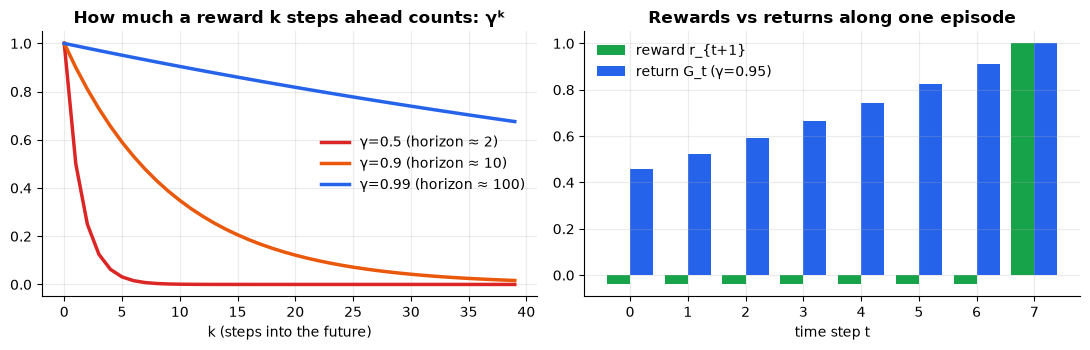

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ks = np.arange(40)
for gamma, color in [(0.5, COLORS["penalty"]), (0.9, COLORS["value"]), (0.99, COLORS["policy"])]:
    axes[0].plot(ks, gamma ** ks, lw=2.5, color=color, label=f"γ={gamma} (horizon ≈ {1 / (1 - gamma):.0f})")
axes[0].set_title("How much a reward k steps ahead counts: γᵏ")
axes[0].set_xlabel("k (steps into the future)"); axes[0].legend()

G = discounted_return(rewards, 0.95)
t = np.arange(len(rewards))
axes[1].bar(t - 0.2, rewards, width=0.4, color=COLORS["reward"], label="reward r_{t+1}")
axes[1].bar(t + 0.2, G, width=0.4, color=COLORS["policy"], label="return G_t (γ=0.95)")
axes[1].set_title("Rewards vs returns along one episode")
axes[1].set_xlabel("time step t"); axes[1].legend()
plt.tight_layout()
save_figure(fig, "00_discounting.png")
plt.show()

Notice in the right panel: the return is *high even at early steps* although those rewards are negative.
The return carries information about the future back to the present. That is credit assignment in one
picture.

## 4. Value functions: "how good is it to be here?"

Returns are random (the policy samples actions, the environment slips). Value functions are their
**expectations**:

* **State value** $V^\pi(s) = \mathbb{E}_\pi[G_t \mid s_t = s]$: expected return when starting in $s$ and following $\pi$.
* **Action value** $Q^\pi(s, a) = \mathbb{E}_\pi[G_t \mid s_t = s, a_t = a]$: same, but the first action is forced to be $a$.
* **Advantage** $A^\pi(s, a) = Q^\pi(s, a) - V^\pi(s)$: how much *better than average* action $a$ is in $s$.

The advantage is the star of the whole course: policy gradients, PPO, GRPO all push up the probability of
actions with $A > 0$ and push down actions with $A < 0$.

The two value functions are related by two simple identities:

$$V^\pi(s) = \sum_a \pi(a \mid s)\, Q^\pi(s, a) \qquad\text{(average over the policy's action choice)}$$

$$Q^\pi(s, a) = \sum_{s', r} P(s', r \mid s, a)\,\big[r + \gamma V^\pi(s')\big] \qquad\text{(one step of the environment, then follow } \pi\text{)}$$

### 4.1 Deriving the Bellman expectation equation

Start from the definition and use the recursive return $G_t = r_{t+1} + \gamma G_{t+1}$:

$$
\begin{aligned}
V^\pi(s) &= \mathbb{E}_\pi[G_t \mid s_t = s] = \mathbb{E}_\pi[r_{t+1} + \gamma G_{t+1} \mid s_t = s] \\
&= \sum_a \pi(a \mid s) \sum_{s', r} P(s', r \mid s, a)\Big[r + \gamma\, \mathbb{E}_\pi[G_{t+1} \mid s_{t+1} = s']\Big] \quad \text{(law of total expectation + Markov)} \\
&= \sum_a \pi(a \mid s) \sum_{s', r} P(s', r \mid s, a)\,\big[r + \gamma V^\pi(s')\big].
\end{aligned}
$$

This is the **Bellman expectation equation**: the value of a state equals the expected immediate reward
plus the discounted value of where you land. It is one linear equation per state, so for a known MDP we
could solve it with linear algebra. Instead we use the simpler fixed-point iteration below, because the
same idea ("make $V(s)$ agree with $r + \gamma V(s')$") reappears as TD learning, Q-learning, the critic in
PPO and the value head of an RLHF model.

```mermaid
flowchart TD
    s(("s")) -->|"π(a₁|s)"| a1["a₁"]
    s -->|"π(a₂|s)"| a2["a₂"]
    a1 -->|"P(s'|s,a₁), r"| s1(("s'₁"))
    a1 -->|"P(s'|s,a₁), r"| s2(("s'₂"))
    a2 -->|"P(s'|s,a₂), r"| s3(("s'₃"))
    s1 -.->|"γ·V(s'₁)"| back["V(s) = Σₐ π · Σ P · (r + γ V(s'))"]
    s2 -.->|"γ·V(s'₂)"| back
    s3 -.->|"γ·V(s'₃)"| back
```

This picture is called a **backup diagram**: value information flows *backwards* from successor states to
the current state.

## 5. Algorithm 1: Iterative policy evaluation

**Goal:** given a fixed policy $\pi$ and a known model $P$, compute $V^\pi$.

> **Algorithm steps: policy evaluation**
> 1. **Initialise** $V(s) = 0$ for all states. *(Any start works: the update is a contraction, so it converges from anywhere.)*
> 2. **Sweep** over every non-terminal state $s$ and compute the right-hand side of the Bellman equation
>    $V_{\text{new}}(s) = \sum_a \pi(a|s) \sum_{s'} P(s'|s,a)[r + \gamma V(s')]$. *(We use the old $V$ on the right: a "synchronous" sweep.)*
> 3. **Measure the change** $\Delta = \max_s |V_{\text{new}}(s) - V(s)|$ and set $V \leftarrow V_{\text{new}}$.
> 4. **Repeat** 2-3 until $\Delta < \theta$ (a small tolerance). *(Each sweep shrinks the error by at least a factor $\gamma$.)*
> 5. Terminal states keep $V = 0$: there is no future after the episode ends.

Why does it converge? The Bellman operator $T^\pi V = r + \gamma P^\pi V$ is a **$\gamma$-contraction** in the
max-norm: $\|T^\pi V - T^\pi U\|_\infty \le \gamma \|V - U\|_\infty$. Applying it repeatedly shrinks the
distance to the unique fixed point $V^\pi$ geometrically.

In [7]:
def policy_evaluation(env, policy_probs, theta=1e-8, max_sweeps=10_000):
    """Iterative policy evaluation (synchronous sweeps).

    policy_probs(s) -> list of 4 action probabilities. Returns (V, number_of_sweeps).
    """
    V = {s: 0.0 for s in env.states}
    for sweep in range(1, max_sweeps + 1):
        V_new = {}
        for s in env.states:
            if s in env.terminal:
                V_new[s] = 0.0
                continue
            V_new[s] = sum(
                pa * sum(p * (r + env.gamma * V[s2] * (not done)) for p, s2, r, done in env.transitions(s, a))
                for a, pa in enumerate(policy_probs(s))
            )
        delta = max(abs(V_new[s] - V[s]) for s in env.states)
        V = V_new
        if delta < theta:
            return V, sweep
    return V, max_sweeps


uniform = lambda s: [0.25, 0.25, 0.25, 0.25]
V_random, sweeps = policy_evaluation(env, uniform)
print(f"uniform-random policy evaluated in {sweeps} sweeps;  V(start) = {V_random[env.start]:+.3f}")

uniform-random policy evaluated in 236 sweeps;  V(start) = -0.763


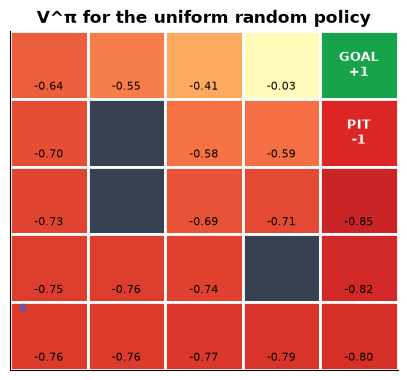

In [8]:
fig, ax = plt.subplots(figsize=(5, 4.4))
draw_grid(ax, env, V_random, title="V^π for the uniform random policy")
plt.show()

The random policy is *bad*: it stumbles into the pit often, so most values are negative. To improve it we
need the *optimal* value function.

## 6. Optimality: the Bellman optimality equation and value iteration

The **optimal value** $V^*(s) = \max_\pi V^\pi(s)$ is the best expected return achievable from $s$. An
optimal agent picks the best action instead of averaging over $\pi$, which turns the sum over actions into
a max:

$$V^*(s) = \max_a \sum_{s', r} P(s', r \mid s, a)\,\big[r + \gamma V^*(s')\big], \qquad Q^*(s, a) = \sum_{s', r} P(s', r \mid s,a)\big[r + \gamma \max_{a'} Q^*(s', a')\big].$$

Once we know $V^*$ (or $Q^*$), acting optimally is easy: be **greedy**,
$\pi^*(s) = \arg\max_a Q^*(s,a)$. Value iteration simply turns the optimality equation into an update.

> **Algorithm steps: value iteration** (Bellman 1957)
> 1. **Initialise** $V(s) = 0$.
> 2. **Bellman optimality backup** for every non-terminal $s$: compute $Q(s,a) = \sum_{s'} P(s'|s,a)[r + \gamma V(s')]$ for each action and set $V_{\text{new}}(s) = \max_a Q(s,a)$.
> 3. **Check convergence** with $\Delta = \max_s |V_{\text{new}}(s) - V(s)|$. Stop when $\Delta < \theta$.
> 4. **Extract the policy**: $\pi(s) = \arg\max_a Q(s,a)$ using the final $V$.
>
> *Intuition:* after $k$ sweeps, $V$ is the optimal value of a game that lasts $k$ steps. The goal's +1
> "spreads" one cell per sweep across the grid: watch it in the animation below.

In [9]:
def q_from_v(env, V, s):
    """One-step look-ahead: Q(s, a) for all actions, using the model."""
    return [sum(p * (r + env.gamma * V[s2] * (not done)) for p, s2, r, done in env.transitions(s, a))
            for a in range(4)]


def value_iteration(env, theta=1e-8, max_sweeps=1000):
    """Returns the optimal V, the greedy policy, and the history of V after every sweep (for the GIF)."""
    V = {s: 0.0 for s in env.states}
    history = [dict(V)]
    for _ in range(max_sweeps):
        V_new = {s: (0.0 if s in env.terminal else max(q_from_v(env, V, s))) for s in env.states}
        delta = max(abs(V_new[s] - V[s]) for s in env.states)
        V = V_new
        history.append(dict(V))
        if delta < theta:
            break
    policy = {s: int(np.argmax(q_from_v(env, V, s))) for s in env.states if s not in env.terminal}
    return V, policy, history


V_star, pi_star, vi_history = value_iteration(env)
deltas = [max(abs(b[s] - a[s]) for s in env.states) for a, b in zip(vi_history, vi_history[1:])]
print(f"value iteration converged in {len(vi_history) - 1} sweeps;  V*(start) = {V_star[env.start]:+.3f}")
assert deltas[-1] < 1e-8
assert V_star[env.start] > V_random[env.start] + 0.5, "optimal values must beat the random policy by a lot"

value iteration converged in 37 sweeps;  V*(start) = +0.310


The animation below shows value iteration *thinking*: each frame is one sweep. Colour is $V(s)$, arrows are
the greedy action under the current $V$, and the right panel is the size of the update $\Delta$ on a log
scale (it drops by roughly a factor $\gamma$ per sweep, as the contraction argument promised).


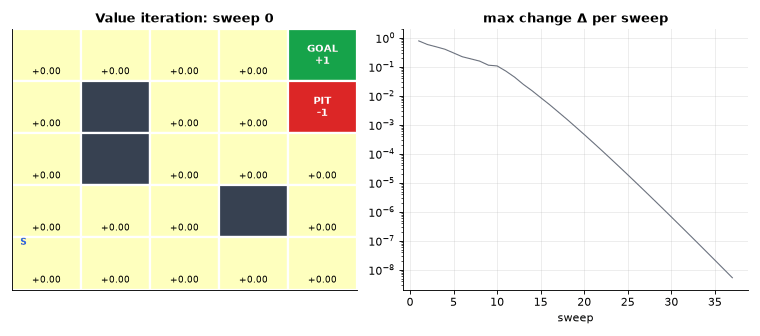

PosixPath('/Users/naveenkumarbasaanitha/Music/HaloDiffusionLLM/assets/rl/course/00_value_iteration.gif')

In [10]:
def greedy_policy(env, V):
    return {s: int(np.argmax(q_from_v(env, V, s))) for s in env.states if s not in env.terminal}


n_vi_frames = min(len(vi_history), 40)
frame_ids = sorted(set(np.unique(np.geomspace(1, len(vi_history) - 1, n_vi_frames).astype(int))) | {0})


def draw_value_iteration(fig, i):
    fig.clf()
    k = frame_ids[min(i, len(frame_ids) - 1)]
    ax1, ax2 = fig.add_subplot(1, 2, 1), fig.add_subplot(1, 2, 2)
    V = vi_history[k]
    draw_grid(ax1, env, V, greedy_policy(env, V) if k > 0 else None, title=f"Value iteration: sweep {k}")
    ax2.semilogy(range(1, len(deltas) + 1), deltas, color=COLORS["reference"], lw=1)
    if k > 0:
        ax2.semilogy(range(1, k + 1), deltas[:k], color=COLORS["accent"], lw=2.5)
        ax2.scatter([k], [deltas[k - 1]], color=COLORS["accent"], zorder=5)
    ax2.set_title("max change Δ per sweep"); ax2.set_xlabel("sweep")
    fig.tight_layout()


Animator(draw_value_iteration, n_frames=len(frame_ids) + 4, figsize=(9.5, 4.2), fps=4).save("00_value_iteration.gif")

Things to notice in the animation:

* In sweep 1 only the cells **next to the goal and pit** change: information travels one step per sweep.
* The arrows near the pit point *away from it* even when the shortest route passes next to it, because a
  slip (20%) could drop the agent in. The optimal policy is **risk-aware** because the model is stochastic.
* Long after the arrows stop changing, the values are still being refined. The *policy* converges before the
  *values* do: that observation is the motivation for policy iteration.

## 7. Algorithm 3: Policy iteration

Policy iteration alternates two steps that each do something we already know how to do.

```mermaid
flowchart LR
    P0["π₀ (any policy,<br/>e.g. random)"] --> E["<b>Evaluate</b><br/>compute V^π<br/>(policy evaluation)"]
    E --> I["<b>Improve</b><br/>π'(s) = argmaxₐ Q^π(s,a)<br/>(act greedily)"]
    I -->|"policy changed"| E
    I -->|"policy stable"| Done["π* and V*"]
```

> **Algorithm steps: policy iteration** (Howard 1960)
> 1. **Start** with any policy $\pi_0$ (we use "always go up").
> 2. **Policy evaluation:** compute $V^{\pi_k}$ exactly (section 5).
> 3. **Policy improvement:** for every state set $\pi_{k+1}(s) = \arg\max_a Q^{\pi_k}(s, a)$.
> 4. **Stop** when $\pi_{k+1} = \pi_k$; that policy is optimal. Otherwise go to step 2.
>
> **Why it works (policy improvement theorem):** if $Q^{\pi}(s, \pi'(s)) \ge V^\pi(s)$ for all $s$, then
> $V^{\pi'}(s) \ge V^\pi(s)$ for all $s$. Acting greedily w.r.t. $Q^\pi$ satisfies the condition by
> construction, so every iteration is at least as good as the last; with finitely many deterministic
> policies it must terminate, and when nothing changes the Bellman *optimality* equation holds.

This "evaluate, then improve" pattern is called **generalised policy iteration** and it is the skeleton of
almost every RL algorithm: actor-critic methods (and PPO-RLHF) do a little bit of evaluation (train the
critic) and a little bit of improvement (a policy-gradient step) at the same time.

policy iteration: 4 evaluate/improve rounds
policy iteration and value iteration agree on 20/20 states


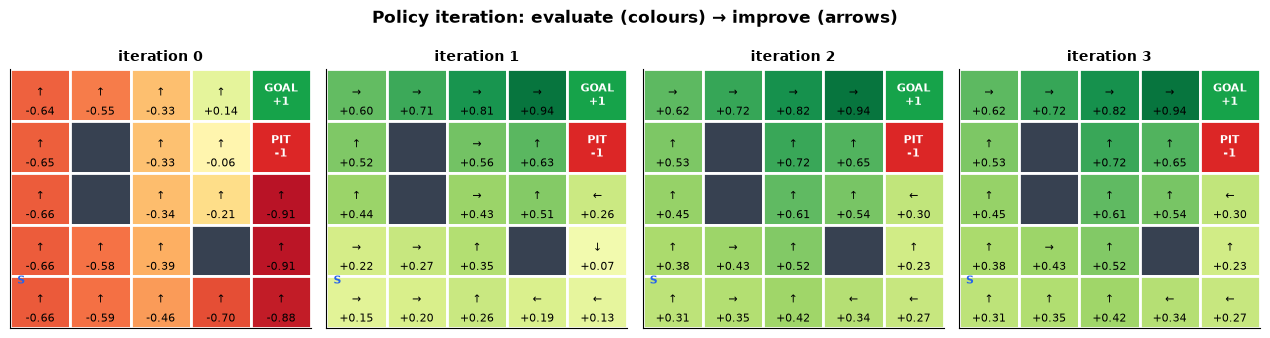

In [11]:
def policy_iteration(env, max_iters=100):
    """Exact policy iteration. Returns the final V, policy, and a list of (V, policy) per iteration."""
    policy = {s: 0 for s in env.states if s not in env.terminal}   # "always go up"
    trace = []
    for _ in range(max_iters):
        V, _ = policy_evaluation(env, lambda s: [float(a == policy.get(s, 0)) for a in range(4)])
        trace.append((V, dict(policy)))
        new_policy = greedy_policy(env, V)
        if new_policy == policy:
            return V, policy, trace
        policy = new_policy
    return V, policy, trace


V_pi, pi_pi, pi_trace = policy_iteration(env)
print(f"policy iteration: {len(pi_trace)} evaluate/improve rounds")
same = sum(pi_pi[s] == pi_star[s] for s in pi_star)
print(f"policy iteration and value iteration agree on {same}/{len(pi_star)} states")
assert all(abs(V_pi[s] - V_star[s]) < 1e-5 for s in env.states), "both methods must find the same V*"

fig, axes = plt.subplots(1, len(pi_trace), figsize=(3.2 * len(pi_trace), 3.4))
for k, (ax, (V, pol)) in enumerate(zip(np.atleast_1d(axes), pi_trace)):
    draw_grid(ax, env, V, pol, title=f"iteration {k}")
    ax.title.set_fontsize(10)
    for t in ax.texts:
        t.set_fontsize(min(t.get_fontsize(), 8))
plt.suptitle("Policy iteration: evaluate (colours) → improve (arrows)", weight="bold")
plt.tight_layout()
save_figure(fig, "00_policy_iteration.png")
plt.show()

Policy iteration needs only a handful of rounds (each round is expensive: a full evaluation), while value
iteration needs many cheap sweeps. Both reach the same $V^*$.

## 8. From planning to learning: Monte Carlo check of $V^*$

Everything above used the **model** $P(s' \mid s, a)$: that is *planning* (dynamic programming). Real RL
agents (and LLMs) usually do not have the model; they only get **samples** by acting. The simplest
model-free estimate of a value is to *average sampled returns* (Monte Carlo):

$$V^\pi(s) \approx \frac{1}{N} \sum_{i=1}^N G^{(i)}, \qquad G^{(i)} \text{ = return of the } i\text{-th episode started in } s.$$

Let's verify our $V^*$ by actually running the optimal policy 2000 times with the `step` function that a
model-free agent would use. The animation compares a random agent and the optimal agent walking in the
world (same random seed for the slips).

In [12]:
def rollout(env, act, rng, max_steps=60):
    s, traj, rewards = env.start, [env.start], []
    for _ in range(max_steps):
        s, r, done = env.step(s, act(s), rng)
        traj.append(s); rewards.append(r)
        if done:
            break
    return traj, rewards


rng = random.Random(1)
mc_returns = [discounted_return(rollout(env, lambda s: pi_star[s], rng)[1], env.gamma)[0] for _ in range(2000)]
mc_mean = sum(mc_returns) / len(mc_returns)
mc_se = (sum((g - mc_mean) ** 2 for g in mc_returns) / len(mc_returns)) ** 0.5 / len(mc_returns) ** 0.5
print(f"Monte Carlo estimate of V*(start) = {mc_mean:+.3f} ± {2 * mc_se:.3f}   (dynamic programming: {V_star[env.start]:+.3f})")
assert abs(mc_mean - V_star[env.start]) < 4 * mc_se + 0.01

Monte Carlo estimate of V*(start) = +0.312 ± 0.009   (dynamic programming: +0.310)



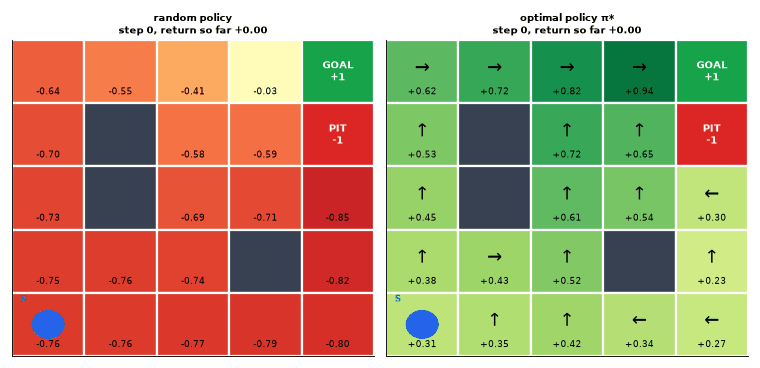

PosixPath('/Users/naveenkumarbasaanitha/Music/HaloDiffusionLLM/assets/rl/course/00_rollouts.gif')

In [13]:
rng_a = random.Random(7)
traj_rand, rew_rand = rollout(env, lambda s: rng_a.randrange(4), random.Random(3))
traj_opt, rew_opt = rollout(env, lambda s: pi_star[s], random.Random(3))
T = max(len(traj_rand), len(traj_opt))
n_frames = min(T, 60)


def draw_rollouts(fig, i):
    fig.clf()
    for j, (name, traj, rew, V, pol) in enumerate([("random policy", traj_rand, rew_rand, V_random, None),
                                                   ("optimal policy π*", traj_opt, rew_opt, V_star, pi_star)]):
        ax = fig.add_subplot(1, 2, j + 1)
        t = min(int(i * T / n_frames), len(traj) - 1)
        G = sum(env.gamma ** k * r for k, r in enumerate(rew[:t]))
        status = ""
        if t == len(traj) - 1:
            status = " - reached GOAL" if traj[-1] in env.terminal and env.terminal[traj[-1]] > 0 else (
                " - fell in PIT" if traj[-1] in env.terminal else " - timeout")
        draw_grid(ax, env, V, pol, agent=traj[t], trail=traj[: t + 1],
                  title=f"{name}\nstep {t}, return so far {G:+.2f}{status}")
        ax.title.set_fontsize(9)
    fig.tight_layout()


Animator(draw_rollouts, n_frames=n_frames + 5, figsize=(9.5, 4.6), fps=5).save("00_rollouts.gif")

## 9. The big picture: an LLM is a policy in a token MDP

Now the key step for the rest of the course. Generating a response with a language model **is** acting in an
MDP:

| MDP concept | LLM text generation |
|---|---|
| state $s_t$ | prompt $x$ + tokens generated so far $y_{<t}$ |
| action $a_t$ | next token $y_t \in$ vocabulary (≈ 32k-256k actions!) |
| policy $\pi_\theta(a_t \mid s_t)$ | the LM's softmax over the next token |
| transition $P$ | **deterministic**: $s_{t+1} = s_t \oplus y_t$ (append the token) |
| episode end | the model emits `<eos>` (or hits a max length) |
| reward | usually **only at the end**: a reward model / human preference / verifier ("is the answer correct?") |
| $\gamma$ | usually 1 |

For a **VLM** the only change is the initial state: $s_0$ = image tokens + text prompt. Everything else, the
actions (text tokens), the policy, the rewards, stays the same, which is why the same RL algorithms train
both. (We will see this concretely in notebook 12.)

```mermaid
flowchart LR
    subgraph s0["state s₀"]
      P["prompt: 2+2="]
    end
    subgraph s1["state s₁"]
      P1["2+2= 4"]
    end
    subgraph s2["state s₂ (terminal)"]
      P2["2+2= 4 &lt;eos&gt;"]
    end
    s0 -- "action: '4'<br/>π(4|s₀)=0.4" --> s1
    s1 -- "action: '&lt;eos&gt;'<br/>π(eos|s₁)=0.7" --> s2
    s2 -- "verifier" --> R["reward = 1<br/>(answer correct)"]
```

Because the transitions are deterministic and the reward comes at the end, the value functions simplify:

* $V^\pi(s_t)$ = the probability-weighted average final reward of all completions of the prefix $s_t$;
* $Q^\pi(s_t, y_t) = V^\pi(s_t \oplus y_t)$ (choosing a token just *is* moving to the next prefix);
* the advantage $A^\pi(s_t, y_t) = V^\pi(s_t \oplus y_t) - V^\pi(s_t)$ measures how much a single token
  changed the expected final reward. That is *credit assignment at the token level*.

Let's make it completely concrete with a tiny "language model" (a hand-written table of next-token
probabilities, standing in for a pretrained LM) answering `2+2=`. Because the tree of all responses is
small we can compute every value **exactly** with the Bellman equation, the same recursion as before.

In [14]:
VOCAB = ["3", "4", "5", "<eos>"]
MAX_TOKENS = 2


def toy_lm(prefix):
    """A 'pretrained' policy: next-token probabilities given the response tokens so far."""
    if len(prefix) == 0:
        return {"3": 0.30, "4": 0.40, "5": 0.20, "<eos>": 0.10}   # first token: usually a digit
    return {"3": 0.10, "4": 0.10, "5": 0.10, "<eos>": 0.70}       # after a digit: usually stop


def reward(response):
    """A verifiable reward: 1 if the answer (tokens before <eos>) is exactly '4'."""
    answer = [t for t in response if t != "<eos>"]
    return 1.0 if answer == ["4"] else 0.0


def is_terminal(prefix):
    return (len(prefix) > 0 and prefix[-1] == "<eos>") or len(prefix) >= MAX_TOKENS


def value(prefix, policy, cache):
    """Bellman expectation in a deterministic token MDP with terminal reward (gamma = 1):
       V(s) = R(s) if s is terminal else sum_y pi(y|s) * V(s + y)."""
    key = tuple(prefix)
    if key not in cache:
        cache[key] = reward(prefix) if is_terminal(prefix) else sum(
            p * value(prefix + [y], policy, cache) for y, p in policy(prefix).items())
    return cache[key]


V_tok = {}
v0 = value([], toy_lm, V_tok)
print(f"V(prompt) = expected reward of a sampled answer = {v0:.3f}")
for y in VOCAB:
    q = V_tok[(y,)]
    print(f"  token {y!r:8}  Q = V(prefix+token) = {q:.3f}   advantage A = Q - V = {q - v0:+.3f}")

# Monte Carlo agrees: sample complete responses from the toy LM and average their rewards.
rng = random.Random(0)


def sample_response(policy, rng):
    prefix = []
    while not is_terminal(prefix):
        probs = policy(prefix)
        prefix.append(rng.choices(list(probs), weights=list(probs.values()))[0])
    return prefix


mc = sum(reward(sample_response(toy_lm, rng)) for _ in range(20_000)) / 20_000
print(f"Monte Carlo estimate from 20k samples = {mc:.3f}")
assert abs(v0 - 0.4 * 0.7) < 1e-12 and abs(mc - v0) < 0.015

V(prompt) = expected reward of a sampled answer = 0.280
  token '3'       Q = V(prefix+token) = 0.000   advantage A = Q - V = -0.280
  token '4'       Q = V(prefix+token) = 0.700   advantage A = Q - V = +0.420
  token '5'       Q = V(prefix+token) = 0.000   advantage A = Q - V = -0.280
  token '<eos>'   Q = V(prefix+token) = 0.000   advantage A = Q - V = -0.280
Monte Carlo estimate from 20k samples = 0.283


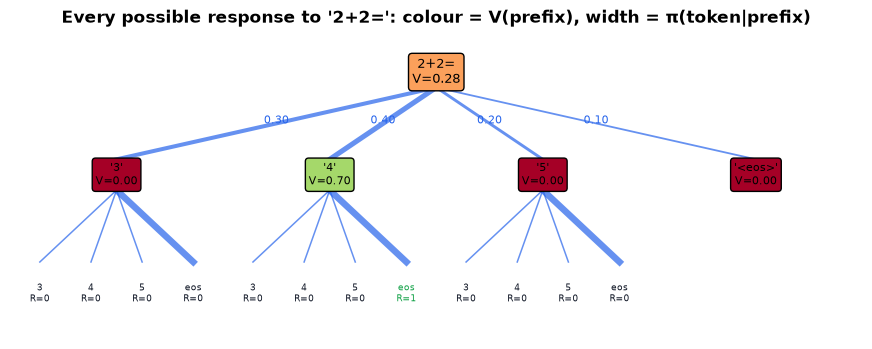

In [15]:
def draw_token_tree(ax, policy, cache, title):
    """Draw the response tree; node colour = V(prefix), edge width = pi(token | prefix)."""
    ax.clear(); ax.axis("off"); ax.set_title(title)
    cmap = plt.get_cmap("RdYlGn")
    ax.text(0, 0, f"2+2=\nV={cache[()]:.2f}", ha="center", va="center", fontsize=9,
            bbox=dict(boxstyle="round", fc=cmap(cache[()]), ec="k"))
    level1 = VOCAB
    for i, y in enumerate(level1):
        x1 = (i - 1.5) * 3.0
        p = policy([])[y]
        ax.plot([0, x1], [-0.15, -0.85], color=COLORS["policy"], lw=0.5 + 8 * p, alpha=0.7)
        ax.text((x1) / 2, -0.5, f"{p:.2f}", fontsize=8, color=COLORS["policy"], ha="center")
        ax.text(x1, -1, f"'{y}'\nV={cache[(y,)]:.2f}", ha="center", va="center", fontsize=8,
                bbox=dict(boxstyle="round", fc=cmap(cache[(y,)]), ec="k"))
        if y == "<eos>":
            continue
        for j, y2 in enumerate(VOCAB):
            x2 = x1 + (j - 1.5) * 0.72
            p2 = policy([y])[y2]
            ax.plot([x1, x2], [-1.15, -1.85], color=COLORS["policy"], lw=0.5 + 6 * p2, alpha=0.7)
            r = cache[(y, y2)]
            ax.text(x2, -2.05, f"{y2.replace('<eos>', 'eos')}\nR={r:.0f}", ha="center", va="top", fontsize=6.5,
                    color=COLORS["reward"] if r > 0 else COLORS["ink"])
    ax.set_xlim(-6, 6); ax.set_ylim(-2.6, 0.4)


fig, ax = plt.subplots(figsize=(11, 4))
draw_token_tree(ax, toy_lm, V_tok, "Every possible response to '2+2=': colour = V(prefix), width = π(token|prefix)")
save_figure(fig, "00_token_tree.png")
plt.show()

What the tree teaches:

* The **reward only exists at the leaves**, but the Bellman recursion gives every intermediate prefix a value.
* The token `4` has a positive advantage ($+0.42$): emitting it raises the expected reward from 0.28 to 0.70.
  The tokens `3` and `5` have advantage $-0.28$: they make success impossible.
* After `4`, the token `<eos>` is what actually locks in the reward; continuing (`4` `4` → "44") destroys it.
* An RL algorithm for LLMs should therefore increase $\pi(\texttt{4} \mid \texttt{2+2=})$ and
  $\pi(\texttt{<eos>} \mid \texttt{2+2=4})$. Notebook 04 does exactly that with gradients.

The optimal policy here is trivial to read off (greedy w.r.t. $Q^*$), but real vocabularies have ~$10^5$
tokens and responses have hundreds of tokens, so the tree has more leaves than atoms in the universe. We
cannot enumerate it; we must **sample** responses and **learn** from their rewards. That is why LLM RL
uses sampling-based, model-free methods (policy gradients, PPO, GRPO) rather than dynamic programming.

In [16]:
def optimal_value(prefix, cache):
    """Bellman optimality in the token MDP: V*(s) = max_y V*(s + y)."""
    key = tuple(prefix)
    if key not in cache:
        cache[key] = reward(prefix) if is_terminal(prefix) else max(optimal_value(prefix + [y], cache) for y in VOCAB)
    return cache[key]


V_opt = {}
print("V*(prompt) =", optimal_value([], V_opt))
greedy = []
while not is_terminal(greedy):
    greedy.append(max(VOCAB, key=lambda y: V_opt[tuple(greedy + [y])]))
print("optimal response (greedy w.r.t. Q*):", greedy)
assert greedy == ["4", "<eos>"]

V*(prompt) = 1.0
optimal response (greedy w.r.t. Q*): ['4', '<eos>']


## 10. A map of RL algorithms (and where LLM methods live)

```mermaid
flowchart TD
    RL["RL algorithms"] --> MB["Model-based / planning<br/>(know P): DP, value & policy iteration<br/><i>this notebook</i>"]
    RL --> MF["Model-free<br/>(only samples)"]
    MF --> VB["Value-based<br/>learn Q, act greedily<br/>MC, TD, SARSA, Q-learning, DQN<br/><i>02, 03</i>"]
    MF --> PB["Policy-based<br/>learn π directly<br/>REINFORCE<br/><i>04</i>"]
    VB --> AC["Actor-critic = both<br/>A2C, GAE, TRPO, PPO<br/><i>05, 06</i>"]
    PB --> AC
    AC --> LLM1["PPO-RLHF<br/><i>07</i>"]
    PB --> LLM2["Critic-free LLM RL<br/>RLOO, GRPO, DAPO<br/><i>09, 10</i>"]
    LLM1 --> DPO["Direct preference opt.<br/>(no sampling loop)<br/>DPO, KTO, SimPO<br/><i>08</i>"]
```

Why do LLM methods sit on the **policy-based** side? Because the action space (the vocabulary) is huge, the
policy is already a great neural network (the pretrained LM) and we want to *fine-tune* it, and the
episodes are short with a terminal reward, so we can afford to sample whole responses.

## 11. Common pitfalls

* **Confusing reward and return (or value).** Reward is one step's signal; return is the sum of future rewards; value is the *expected* return.
* **Forgetting to zero the value of terminal states.** Bootstrapping from $V(\text{terminal}) \ne 0$ leaks fake future reward into the episode end (the `* (not done)` factor in our code).
* **$\gamma = 1$ with infinite episodes** makes returns unbounded; that's fine for LLMs only because responses are capped at a max length.
* **Reward design changes behaviour.** Try `step_reward=-0.5` in the gridworld: the agent will happily jump into the pit to end the pain quickly. The LLM version of this is *reward hacking* (notebook 13).
* **Thinking the optimal policy is "shortest path".** With stochastic dynamics the optimal policy trades speed for safety (look at the arrows next to the pit).
* **Expecting DP to scale.** It needs the model and a sweep over every state; token MDPs have astronomically many states.

## 12. How this connects to LLM/VLM training

* The **reward model** in RLHF (notebook 07) defines $R$ at the terminal state; the **KL penalty** to the reference model adds a small per-token reward.
* The **value head** of PPO-RLHF learns $V^\pi(\text{prefix})$, exactly the colours in the token tree.
* **GRPO** (notebook 09) avoids learning $V$ by estimating it from a *group* of sampled responses per prompt (a Monte Carlo estimate, like section 8).
* **Token-level advantages** decide which tokens get reinforced; the token tree shows why a terminal reward still gives every token a meaningful advantage.
* For **VLMs**, the image tokens are part of the initial state $s_0$; the MDP over text tokens is unchanged.

## 13. Cheat sheet

| Concept | Formula | Code in this notebook |
|---|---|---|
| Return | $G_t = r_{t+1} + \gamma G_{t+1}$ | `discounted_return` |
| State value | $V^\pi(s) = \mathbb{E}_\pi[G_t \mid s_t = s]$ | `policy_evaluation` |
| Action value | $Q^\pi(s,a) = \sum P\,[r + \gamma V^\pi(s')]$ | `q_from_v` |
| Advantage | $A^\pi = Q^\pi - V^\pi$ | token tree section |
| Bellman expectation | $V^\pi = \sum_a \pi \sum P [r + \gamma V^\pi]$ | `policy_evaluation` |
| Bellman optimality | $V^* = \max_a \sum P [r + \gamma V^*]$ | `value_iteration` |
| Policy iteration | evaluate → greedy improve → repeat | `policy_iteration` |
| Monte Carlo value | average of sampled returns | section 8 |
| LLM as MDP | state = prefix, action = token, reward at `<eos>` | `toy_lm`, `value` |

**Next:** notebook 01 strips the MDP down to a single state, the *multi-armed bandit*, to study the other
core difficulty of RL: **exploration vs exploitation**.